# Plots for `brainstorm.md`

One simple chart per finding. Downtown is always blue, Seaside always orange, green means both hotels together.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(Path('train-template-kit') / 'train.csv', parse_dates=['arrival_date', 'booking_date'])
df['value'] = df['nightly_rate'] * df['nights']
df['departure_date'] = df['arrival_date'] + pd.to_timedelta(df['nights'], unit='D')
shows = df[df['cancelled'] == 0]

HOTELS = ['Downtown Hotel', 'Seaside Hotel']
CAPACITY = {'Downtown Hotel': 124, 'Seaside Hotel': 103}
COLOR = {'Downtown Hotel': '#2a78d6', 'Seaside Hotel': '#eb6834', 'both': '#1baf7a'}
INK = '#0b0b0b'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'figure.dpi': 110,
    'text.color': INK, 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.edgecolor': '#c3c2b7',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'axes.axisbelow': True,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlepad': 10,
    'lines.linewidth': 2, 'lines.markersize': 7,
    'lines.markeredgecolor': '#fcfcfb', 'lines.markeredgewidth': 1.5,
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'legend.frameon': False,
})

## 1. Capacity is very tight (§2)

Rooms occupied each night, counting only guests who showed up, against the game's capacity.

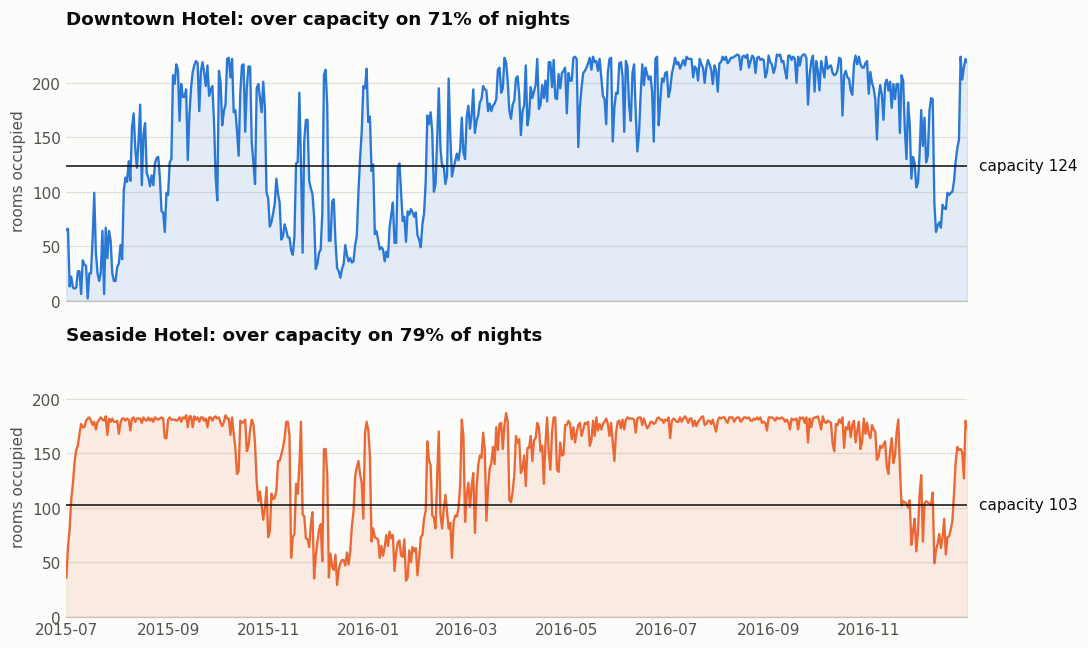

In [2]:
days = pd.date_range('2015-07-01', '2016-12-31')

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, hotel in zip(axes, HOTELS):
    guests = shows[shows['hotel'] == hotel]
    arrivals = guests['arrival_date'].value_counts().reindex(days, fill_value=0)
    departures = guests['departure_date'].value_counts().reindex(days, fill_value=0)
    occupied = (arrivals - departures).cumsum()

    ax.fill_between(days, occupied, color=COLOR[hotel], alpha=0.12)
    ax.plot(days, occupied, color=COLOR[hotel], linewidth=1.5)
    ax.axhline(CAPACITY[hotel], color=INK, linewidth=1)
    ax.annotate(f'capacity {CAPACITY[hotel]}', (days[-1], CAPACITY[hotel]),
                xytext=(8, 0), textcoords='offset points', va='center')
    over = (occupied > CAPACITY[hotel]).mean() * 100
    ax.set_title(f'{hotel}: over capacity on {over:.0f}% of nights')
    ax.set_ylabel('rooms occupied')
    ax.set_ylim(0, 240)
    ax.margins(x=0)
fig.tight_layout()
plt.show()

## 2. Early bookings cancel far more often (§5)

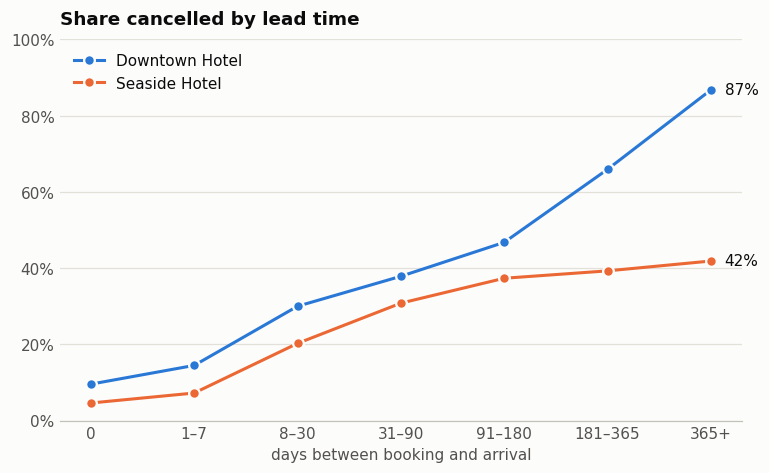

In [3]:
buckets = ['0', '1–7', '8–30', '31–90', '91–180', '181–365', '365+']
df['lead_bucket'] = pd.cut(df['days_ahead'], bins=[-1, 0, 7, 30, 90, 180, 365, 10_000], labels=buckets)
rate = df.groupby(['lead_bucket', 'hotel'], observed=True)['cancelled'].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
for hotel in HOTELS:
    ax.plot(buckets, rate[hotel], marker='o', color=COLOR[hotel], label=hotel)
    ax.annotate(f'{rate[hotel].iloc[-1]:.0f}%', (buckets[-1], rate[hotel].iloc[-1]),
                xytext=(9, 0), textcoords='offset points', va='center')
ax.set_title('Share cancelled by lead time')
ax.set_xlabel('days between booking and arrival')
ax.yaxis.set_major_formatter('{x:.0f}%')
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.show()

## 3. Cancellation by sales segment (§5)

Segments with at least 100 bookings at both hotels.

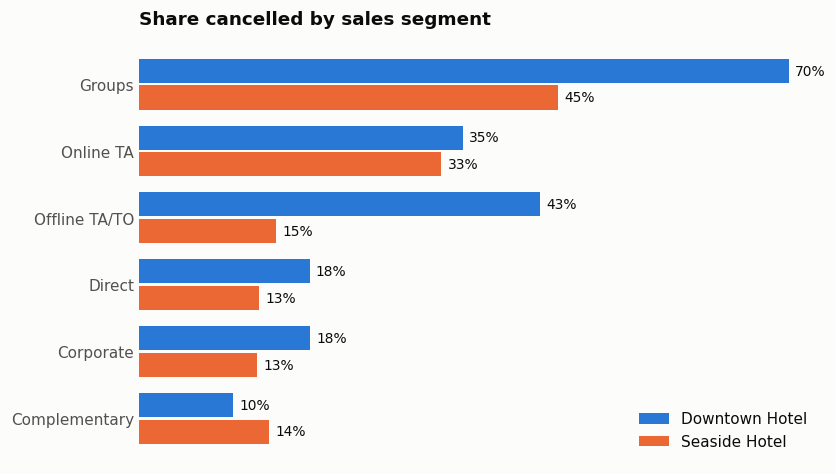

In [4]:
seg = df.groupby(['sales_segment', 'hotel'])['cancelled'].agg(['mean', 'size']).reset_index()
seg = seg[seg['size'] >= 100]
rate = seg.pivot(index='sales_segment', columns='hotel', values='mean').dropna() * 100
rate = rate.loc[rate.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(rate))
for offset, hotel in zip([0.2, -0.2], HOTELS):
    bars = ax.barh(y + offset, rate[hotel], height=0.36, color=COLOR[hotel], label=hotel)
    ax.bar_label(bars, fmt='%.0f%%', padding=4, fontsize=9)
ax.set_yticks(y, rate.index)
ax.set_title('Share cancelled by sales segment')
ax.grid(False)
ax.xaxis.set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.legend(loc='lower right')
plt.show()

## 4. The strongest cancellation signals (§4, §5)

Both hotels together. Several of these fields are filled in after the booking was made, so treat them as hindsight.

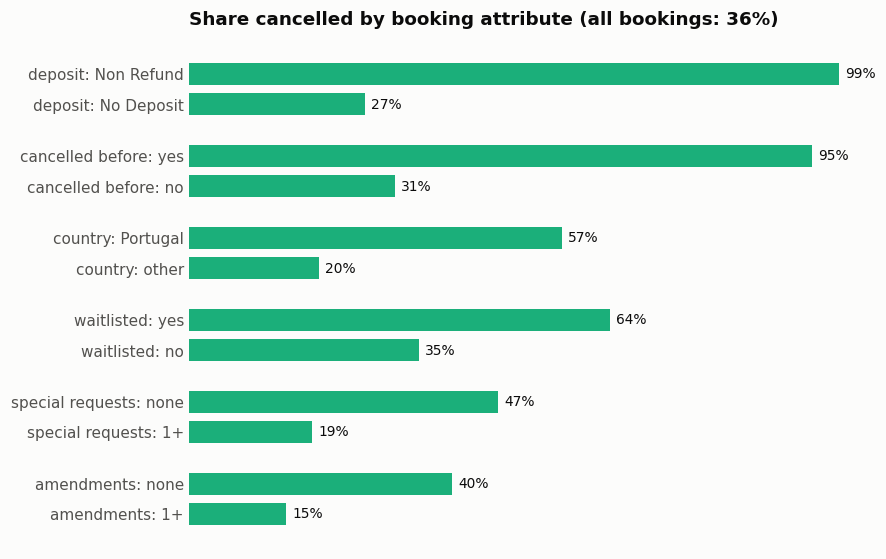

In [5]:
groups = {
    'deposit: Non Refund': df['deposit'] == 'Non Refund',
    'deposit: No Deposit': df['deposit'] == 'No Deposit',
    'cancelled before: yes': df['past_cancellations'] > 0,
    'cancelled before: no': df['past_cancellations'] == 0,
    'country: Portugal': df['country'] == 'PRT',
    'country: other': df['country'].notna() & (df['country'] != 'PRT'),
    'waitlisted: yes': df['waitlist_days'] > 0,
    'waitlisted: no': df['waitlist_days'] == 0,
    'special requests: none': df['special_requests'] == 0,
    'special requests: 1+': df['special_requests'] > 0,
    'amendments: none': df['amendments'] == 0,
    'amendments: 1+': df['amendments'] > 0,
}
rate = pd.Series({name: df.loc[mask, 'cancelled'].mean() * 100 for name, mask in groups.items()})
overall = df['cancelled'].mean() * 100
y = np.arange(len(rate)) + np.arange(len(rate)) // 2 * 0.7

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(y, rate, height=0.72, color=COLOR['both'])
ax.bar_label(bars, fmt='%.0f%%', padding=4, fontsize=9)
ax.set_yticks(y, rate.index)
ax.invert_yaxis()
ax.set_title(f'Share cancelled by booking attribute (all bookings: {overall:.0f}%)')
ax.grid(False)
ax.xaxis.set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.show()

## 5. `booking_id` leaks the outcome (§1)

Each dot is a block of 1,000 consecutive IDs. Dots near 100% or 0% mean the ID alone almost tells you the answer. Stretches with no dots have almost no training rows, most likely because the 2017 rows sit there.

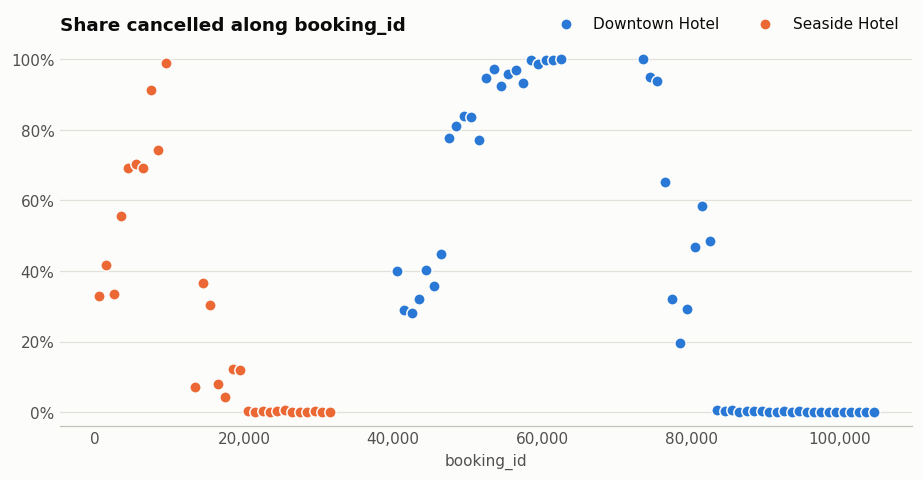

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for hotel in HOTELS:
    h = df[df['hotel'] == hotel]
    blocks = h.groupby(h['booking_id'] // 1000 * 1000 + 500)['cancelled'].agg(['mean', 'size'])
    blocks = blocks[blocks['size'] >= 30]
    ax.scatter(blocks.index, blocks['mean'] * 100, s=55, color=COLOR[hotel], edgecolor='#fcfcfb', label=hotel)
ax.set_title('Share cancelled along booking_id')
ax.set_xlabel('booking_id')
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.yaxis.set_major_formatter('{x:.0f}%')
ax.set_ylim(-4, 104)
ax.legend(loc='lower right', bbox_to_anchor=(1, 1), ncols=2)
plt.show()

## 6. Groups of identical bookings cancel more (§3)

Rows that are identical except for `booking_id`, grouped by how many copies there are.

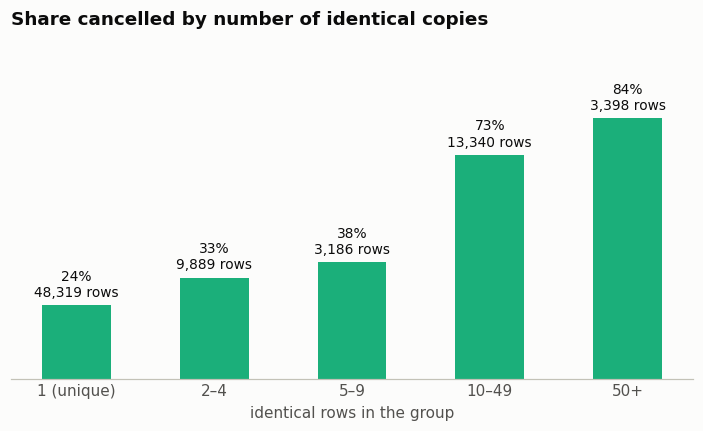

In [7]:
same = [c for c in df.columns if c not in ('booking_id', 'cancelled', 'lead_bucket')]
copies = df.groupby(same, dropna=False)['booking_id'].transform('size')
sizes = ['1 (unique)', '2–4', '5–9', '10–49', '50+']
df['copies'] = pd.cut(copies, bins=[0, 1, 4, 9, 49, 1000], labels=sizes)
dup = df.groupby('copies', observed=True)['cancelled'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(sizes, dup['mean'] * 100, width=0.5, color=COLOR['both'])
ax.bar_label(bars, labels=[f'{m * 100:.0f}%\n{n:,} rows' for m, n in zip(dup['mean'], dup['size'])],
             padding=4, fontsize=9)
ax.set_title('Share cancelled by number of identical copies')
ax.set_xlabel('identical rows in the group')
ax.set_ylim(0, 110)
ax.grid(False)
ax.yaxis.set_visible(False)
plt.show()

## 7. What a stay is worth (§2)

Rate × nights for guests who showed up. Stays above €1,500 are not drawn.

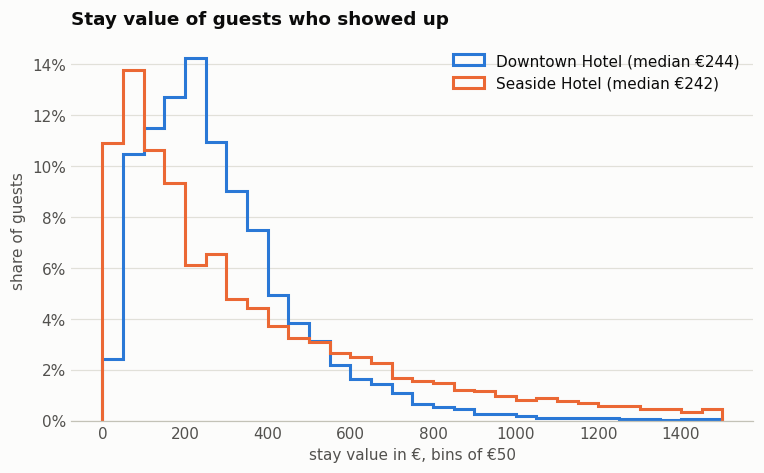

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for hotel in HOTELS:
    value = shows.loc[shows['hotel'] == hotel, 'value']
    ax.hist(value, bins=np.arange(0, 1550, 50), weights=np.full(len(value), 100 / len(value)),
            histtype='step', linewidth=2, color=COLOR[hotel],
            label=f'{hotel} (median €{value.median():.0f})')
ax.set_title('Stay value of guests who showed up')
ax.set_xlabel('stay value in €, bins of €50')
ax.yaxis.set_major_formatter('{x:.0f}%')
ax.set_ylabel('share of guests')
ax.legend()
plt.show()

## 8. Month by month (§8)

Downtown's July–August 2015 looks incomplete, and prices rise from 2015 to 2016.

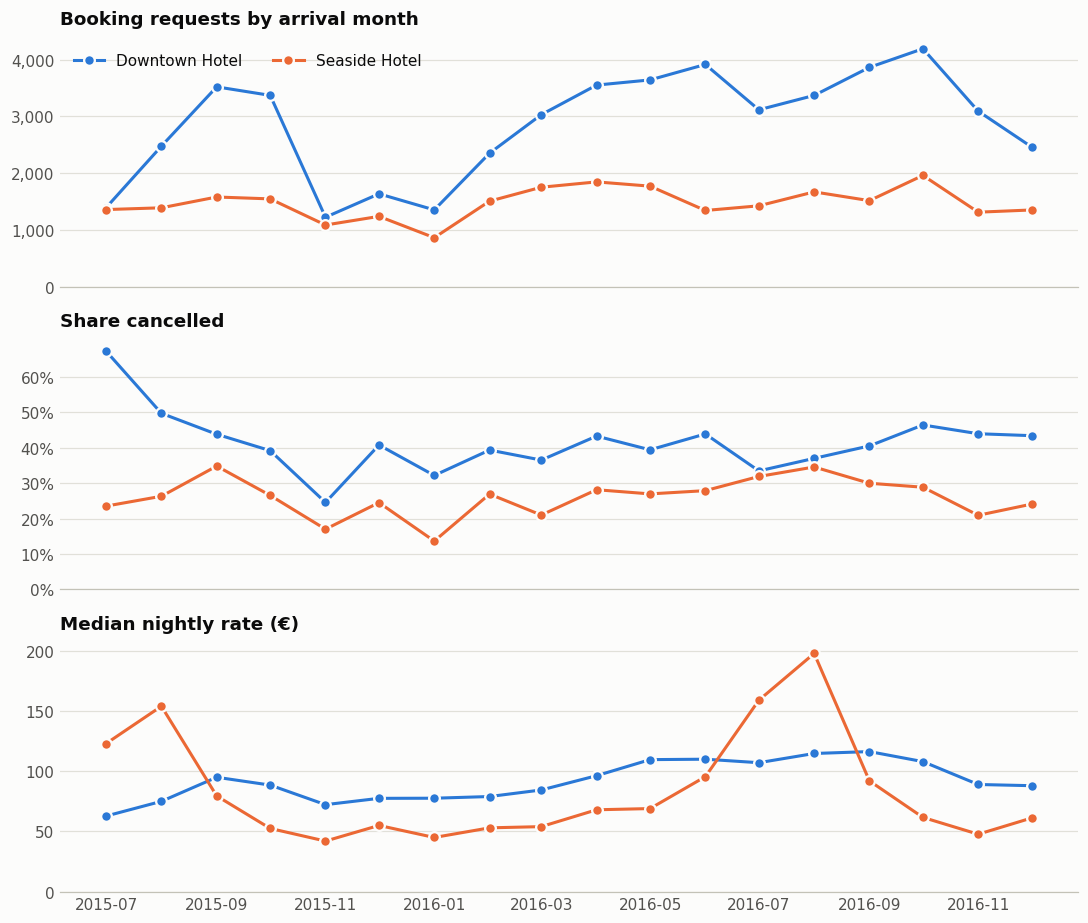

In [9]:
df['month'] = df['arrival_date'].dt.to_period('M').dt.to_timestamp()
monthly = df.groupby(['month', 'hotel']).agg(
    requests=('cancelled', 'size'),
    cancelled=('cancelled', lambda x: x.mean() * 100),
    median_rate=('nightly_rate', 'median'),
)
panels = {
    'requests': 'Booking requests by arrival month',
    'cancelled': 'Share cancelled',
    'median_rate': 'Median nightly rate (€)',
}

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
for ax, (column, title) in zip(axes, panels.items()):
    for hotel in HOTELS:
        line = monthly[column].xs(hotel, level='hotel')
        ax.plot(line.index, line, marker='o', color=COLOR[hotel], label=hotel)
    ax.set_title(title)
    ax.set_ylim(0)
axes[0].yaxis.set_major_formatter('{x:,.0f}')
axes[1].yaxis.set_major_formatter('{x:.0f}%')
axes[0].legend(loc='upper left', ncols=2)
fig.tight_layout()
plt.show()